# Motorbike Detection — YOLOv8

**Dataset:** Roboflow `motobike-detection-otper-h43mq` v1 (CC BY 4.0), YOLOv8 export format.

| Property | Value |
| --- | --- |
| Number of classes | 1 (`motobike`) |
| Image size | 640×640 (auto-oriented + resized with *stretch* by Roboflow) |
| Train / Valid / Test | 1152 / 136 / 67 images |
| Labels | YOLO txt: `class cx cy w h` (normalized 0–1) |
| Existing augmentations | None |

**Key Data Considerations**

* The **test set has no labels**, so it is strictly used for inference. Quantitative evaluation is performed using the validation set.
* Images are **video frame extractions** (`3J4A78xx_frame_NNNN`, `78xx_frame_NNNN`). Consecutive frames are nearly identical.
* Some images are **uploaded multiple times** (different `.rf.` hashes with slightly varying labels), with duplicates scattered across train/valid/test, causing **data leakage**.

**Notebook Contents**

1. Setup & Configuration
2. Dataset Discovery
3. Label EDA
4. Data Quality Checks: Image statistics, label validation, duplicate/leakage detection
5. Preprocessing: Label cleaning, duplicate removal, video-based data splitting, augmentation configuration and preview
6. Training Two Experiments: **A** (Roboflow original split) and **B** (cleaned data + video-based split)
7. Results Comparison, Confidence Threshold Selection, and Error Analysis
8. Inference on Test & Saving Results

> The **Observations** cells record numbers from the Kaggle run of v1, 2026-10-08 (Tesla T4, ultralytics 8.4.174). Update them if a re-run gives different numbers.
> This notebook is kept in 1-to-1 sync with `motorbike_detection.ipynb` (Vietnamese version): cell *k* has the same content in both.

## 1. Installation and Configuration

In [1]:
!pip install -q ultralytics
import ultralytics, torch
ultralytics.checks()
print("CUDA:", torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Setup complete ✅ (4 CPUs, 31.3 GB RAM, 7087.0/8156.9 GB disk)
CUDA: True Tesla T4


In [5]:
import os, re, glob, random, shutil, warnings
from pathlib import Path
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import cv2
import yaml
from PIL import Image
from IPython.display import display

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3})

SEED = 42
random.seed(SEED); np.random.seed(SEED)

# ---- Training Configuration ----
QUICK = os.environ.get("QUICK_TEST") == "1"     # quick smoke test on CPU, do NOT use on Kaggle
MODEL    = "yolov8n.pt" if QUICK else "yolov8s.pt"   # yolov8n/s/m/l/x
EPOCHS   = 1 if QUICK else 100
IMGSZ    = 320 if QUICK else 640
BATCH    = 8 if QUICK else 16
PATIENCE = 25
FRACTION = 0.1 if QUICK else 1.0
WORKERS  = 0 if QUICK else 4
VAL_FRAC = 0.15          # validation image ratio when splitting by video

WORK = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path.cwd()
DS_ROOT = WORK / "datasets"
RUNS = WORK / "runs"
print("WORK:", WORK)
print("QUICK:", QUICK)

WORK: /kaggle/working
QUICK: False


## 2. Dataset Discovery

In [6]:
search_roots = [os.environ.get("DATA_DIR", ""), "/kaggle/input", str(Path.cwd()), str(Path.cwd() / "data")]
DATA_ROOT = None
for root in filter(None, search_roots):
    for y in sorted(glob.glob(f"{root}/**/data.yaml", recursive=True)):
        p = Path(y).parent
        if (p / "train" / "images").exists() and (p / "valid" / "images").exists():
            DATA_ROOT = p; break
    if DATA_ROOT: break
assert DATA_ROOT is not None, "Dataset not found!"
print("DATA_ROOT:", DATA_ROOT)

orig = yaml.safe_load(open(DATA_ROOT / "data.yaml"))
CLASS_NAMES = orig["names"]
print("Classes:", CLASS_NAMES)

DATA_ROOT: /kaggle/input/datasets/hansrenek/motorbike-detection-yolov8
Classes: ['motobike']


In [7]:
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp")
SPLITS = ["train", "valid", "test"]

def list_images(split):
    return sorted(p for p in (DATA_ROOT / split / "images").glob("*") if p.suffix.lower() in IMG_EXT)

def label_path(img_path):
    return img_path.parent.parent / "labels" / (img_path.stem + ".txt")

def read_labels(img_path):
    # Returns an array (N,5) or None if no label file exists
    lp = label_path(img_path)
    if not lp.exists():
        return None
    rows = [l.split() for l in lp.read_text().strip().splitlines() if l.strip()]
    return np.array(rows, dtype=float).reshape(-1, 5)

def frame_id(name):
    # '7825_frame_0001_png.rf.<hash>.jpg' -> '7825_frame_0001'
    return name.split(".rf.")[0].replace("_png", "").replace("_jpg", "")

def video_id(name):
    # Combine '3J4A7825' and '7825' into a single video '7825'
    m = re.search(r"(\d{4})_frame", name)
    return m.group(1) if m else name.split("_")[0]

meta = pd.DataFrame([
    dict(split=s, path=p, name=p.name, frame=frame_id(p.name), video=video_id(p.name))
    for s in SPLITS for p in list_images(s)
])
meta.groupby("split").size().to_frame("images")

,images
split,
test,67
train,1152
valid,136


## 3. Label EDA (Exploratory Data Analysis)

In [8]:
records, summary = [], []
for split in SPLITS:
    imgs = list_images(split)
    n_lab = n_empty = n_box = 0
    for ip in imgs:
        lab = read_labels(ip)
        if lab is None:
            continue
        n_lab += 1; n_empty += len(lab) == 0; n_box += len(lab)
        for c, cx, cy, w, h in lab:
            records.append(dict(split=split, img=ip.name, cls=int(c), cx=cx, cy=cy, w=w, h=h))
    summary.append(dict(split=split, images=len(imgs), label_files=n_lab, empty_labels=n_empty, boxes=n_box,
                        boxes_per_img=round(n_box / max(n_lab, 1), 2)))

boxes = pd.DataFrame(records)
boxes["area"] = boxes.w * boxes.h
boxes["aspect"] = boxes.h / boxes.w
display(pd.DataFrame(summary))
display(boxes.groupby("split")[["w", "h", "area", "aspect"]].describe().T.round(3))

,split,images,label_files,empty_labels,boxes,boxes_per_img
0,train,1152,1152,1,1723,1.50
1,valid,136,136,0,201,1.48
2,test,67,0,0,0,0.00


split            train    valid
w      count  1723.000  201.000
       mean      0.140    0.142
       std       0.025    0.026
       min       0.070    0.080
       25%       0.123    0.124
       50%       0.142    0.143
       75%       0.157    0.159
       max       0.259    0.216
h      count  1723.000  201.000
       mean      0.525    0.521
       std       0.081    0.087
       min       0.263    0.216
       25%       0.470    0.477
       50%       0.533    0.531
       75%       0.588    0.582
       max       0.741    0.702
area   count  1723.000  201.000
       mean      0.075    0.076
       std       0.022    0.024
       min       0.022    0.017
       25%       0.059    0.059
       50%       0.076    0.076
       75%       0.091    0.094
       max       0.166    0.152
aspect count  1723.000  201.000
       mean      3.773    3.690
       std       0.390    0.375
       min       2.305    2.689
       25%       3.546    3.410
       50%       3.782    3.692
       75%       4.020    3.920
       max       5.743    4.786

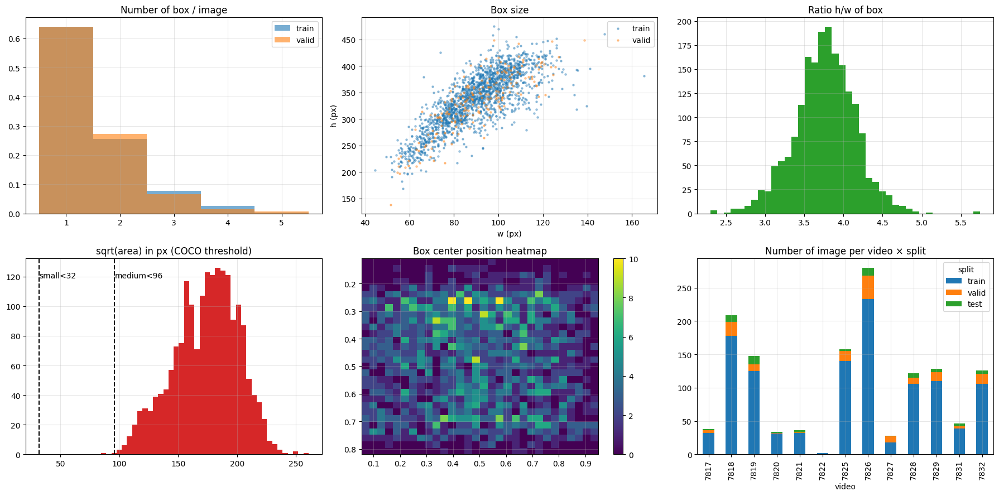

In [10]:
fig, ax = plt.subplots(2, 3, figsize=(18, 9))
per_img = boxes.groupby(["split", "img"]).size()
for s in ["train", "valid"]:
    ax[0, 0].hist(per_img[s], bins=np.arange(.5, per_img.max() + 1.5), alpha=.6, label=s, density=True)
ax[0, 0].set_title("Number of box / image"); ax[0, 0].legend()

for s, c in [("train", "C0"), ("valid", "C1")]:
    d = boxes[boxes.split == s]
    ax[0, 1].scatter(d.w * 640, d.h * 640, s=5, alpha=.4, c=c, label=s)
ax[0, 1].set_xlabel("w (px)"); ax[0, 1].set_ylabel("h (px)"); ax[0, 1].set_title("Box size"); ax[0, 1].legend()

ax[0, 2].hist(boxes.aspect, bins=40, color="C2"); ax[0, 2].set_title("Ratio h/w of box")

ax[1, 0].hist(np.sqrt(boxes.area) * 640, bins=40, color="C3")
for t, lbl in [(32, "small<32"), (96, "medium<96")]:
    ax[1, 0].axvline(t, ls="--", c="k"); ax[1, 0].text(t, ax[1, 0].get_ylim()[1] * .9, lbl)
ax[1, 0].set_title("sqrt(area) in px (COCO threshold)")

h = ax[1, 1].hist2d(boxes.cx, boxes.cy, bins=30, cmap="viridis"); ax[1, 1].invert_yaxis()
ax[1, 1].set_title("Box center position heatmap"); plt.colorbar(h[3], ax=ax[1, 1])

vc = pd.crosstab(meta.video, meta.split)[SPLITS]
vc.plot.bar(stacked=True, ax=ax[1, 2]); ax[1, 2].set_title("Number of image per video × split")
plt.tight_layout(); plt.show()

**Observations (Kaggle run of v1, 2026-10-08)**
- About 1.5 boxes/image on average → sparse scenes, most images contain 1–2 motorbikes.
- Median box: w ≈ 0.14, h ≈ 0.53 (≈ 90×340 px), h/w ratio ≈ 3.8 → boxes are **tall and narrow**.
- √area ≈ 175 px → almost every box is a **large** object by the COCO threshold (> 96 px), so no small-object tricks are needed.
- ⚠️ Roboflow resized the images to 640×640 with **stretch** (aspect ratio not preserved). If the source frames were 16:9, the width was squeezed more than the height, so part of the 3.8 ratio may be geometric distortion. When running on raw video frames, apply the same **stretch** resize before feeding the model (Ultralytics letterboxes by default, which preserves the ratio). The test images are already stretched, so Section 8 is not affected.

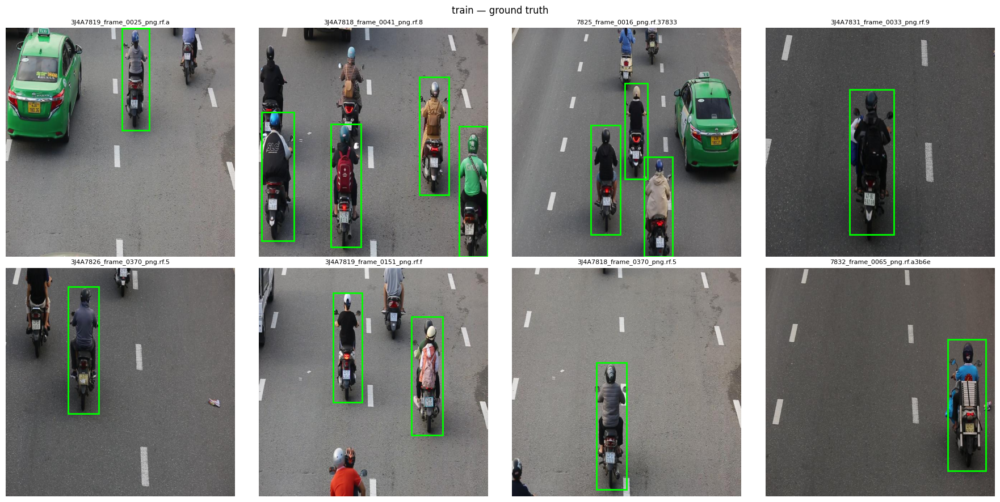

In [11]:
def draw_boxes(ax, img_path, lab, color="lime"):
    im = Image.open(img_path); W, H = im.size
    ax.imshow(im); ax.axis("off")
    if lab is not None:
        for c, cx, cy, w, h in lab:
            ax.add_patch(patches.Rectangle(((cx - w / 2) * W, (cy - h / 2) * H), w * W, h * H, fill=False, ec=color, lw=2))

def show_samples(split, n=8, cols=4):
    imgs = random.sample(list_images(split), min(n, len(list_images(split))))
    rows = int(np.ceil(len(imgs) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4.5 * cols, 4.5 * rows))
    for ax, ip in zip(np.ravel(axes), imgs):
        draw_boxes(ax, ip, read_labels(ip)); ax.set_title(ip.name[:28], fontsize=8)
    for ax in np.ravel(axes)[len(imgs):]: ax.axis("off")
    plt.suptitle(f"{split} — ground truth"); plt.tight_layout(); plt.show()

show_samples("train")

## 4. Data Quality Check

### 4.1 Image Statistics: Brightness, Contrast, Sharpness

* **Brightness** = Mean grayscale value; **Contrast** = Standard deviation of grayscale values; **Sharpness** = Laplacian variance (low values indicate blurriness).
* If the distributions across splits are skewed or widely spread, color augmentations (`hsv_v`, `hsv_s`) should be increased.

split               test   train   valid
brightness count    67.0  1152.0   136.0
           mean    103.6   101.6    99.8
           std      19.4    17.4    16.2
           min      66.1    57.2    67.1
           25%      86.2    88.6    87.8
           50%     103.6   102.4   101.3
           75%     119.0   115.0   110.8
           max     135.8   149.4   131.7
contrast   count    67.0  1152.0   136.0
           mean     26.4    25.9    25.4
           std       5.8     6.0     5.4
           min      16.9    15.2    16.2
           25%      21.7    21.7    21.5
           50%      26.1    25.0    24.2
           75%      30.3    29.3    29.2
           max      39.5    54.3    42.0
sharpness  count    67.0  1152.0   136.0
           mean    709.2   641.5   636.5
           std     287.5   263.3   251.9
           min     270.8   181.3   253.4
           25%     473.3   402.8   405.8
           50%     720.8   652.3   657.6
           75%     945.9   807.5   776.9
           max    1397.9  1554.0  1401.7

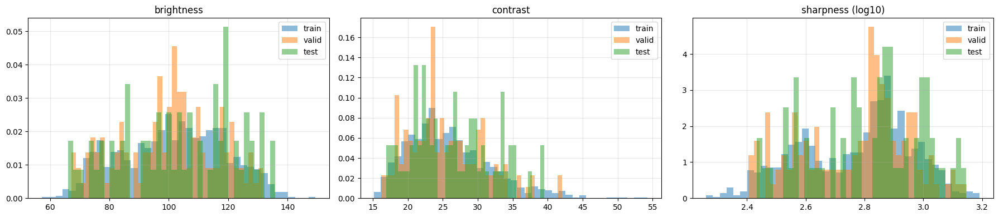

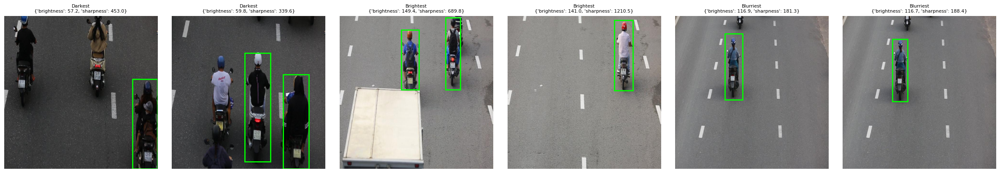

In [12]:
def img_stats(p):
    g = cv2.imread(str(p), cv2.IMREAD_GRAYSCALE)
    return g.mean(), g.std(), cv2.Laplacian(g, cv2.CV_64F).var()

meta[["brightness", "contrast", "sharpness"]] = np.array([img_stats(p) for p in meta.path])
display(meta.groupby("split")[["brightness", "contrast", "sharpness"]].describe().T.round(1))

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for i, col in enumerate(["brightness", "contrast", "sharpness"]):
    for s in SPLITS:
        v = meta.loc[meta.split == s, col]
        ax[i].hist(np.log10(v + 1) if col == "sharpness" else v, bins=40, alpha=.5, density=True, label=s)
    ax[i].set_title(col + (" (log10)" if col == "sharpness" else "")); ax[i].legend()
plt.tight_layout(); plt.show()

# Images at the two extremes (darkest / brightest / blurriest)
picks = [("Darkest", meta.nsmallest(2, "brightness")), ("Brightest", meta.nlargest(2, "brightness")),
         ("Blurriest", meta.nsmallest(2, "sharpness"))]
fig, axes = plt.subplots(1, 6, figsize=(24, 4))
k = 0
for title, df in picks:
    for _, r in df.iterrows():
        draw_boxes(axes[k], r.path, read_labels(r.path)); axes[k].set_title(f"{title}\n{r[['brightness','sharpness']].astype(float).round(1).to_dict()}", fontsize=8); k += 1
plt.tight_layout(); plt.show()

**Observations (Kaggle run of v1, 2026-10-08)**
- Mean brightness ≈ 100/255 (slightly dark), contrast (std) ≈ 26 (low), sharpness (Laplacian variance) ≈ 640.
- Train/valid/test distributions almost overlap → **no distribution shift** in lighting or sharpness between splits. HSV augmentation is still useful, but its purpose is to prepare for new cameras/lighting, not to fix a gap between splits.

### 4.2 Label Validation

Checked errors include: coordinates out of bounds $[0,1]$, boxes clipped outside the image, excessively small or degenerate boxes, overlapping/duplicate boxes within the same image, invalid class IDs, and unlabeled images.

In [13]:
def iou_xywh(a, b):
    ax1, ay1, ax2, ay2 = a[0] - a[2] / 2, a[1] - a[3] / 2, a[0] + a[2] / 2, a[1] + a[3] / 2
    bx1, by1, bx2, by2 = b[0] - b[2] / 2, b[1] - b[3] / 2, b[0] + b[2] / 2, b[1] + b[3] / 2
    iw, ih = max(0, min(ax2, bx2) - max(ax1, bx1)), max(0, min(ay2, by2) - max(ay1, by1))
    inter = iw * ih
    return inter / (a[2] * a[3] + b[2] * b[3] - inter + 1e-9)

MIN_WH = 0.005   # A box smaller than 0.5% of the image side length (~3px) is considered an error.
issues = []
for _, r in meta[meta.split != "test"].iterrows():
    lab = read_labels(r.path)
    if lab is None or len(lab) == 0:
        issues.append(dict(split=r.split, name=r["name"], issue="empty_label")); continue
    for i, (c, cx, cy, w, h) in enumerate(lab):
        if int(c) not in range(len(CLASS_NAMES)): issues.append(dict(split=r.split, name=r["name"], issue="bad_class"))
        if not (0 <= cx <= 1 and 0 <= cy <= 1): issues.append(dict(split=r.split, name=r["name"], issue="center_out_of_range"))
        if cx - w / 2 < -1e-3 or cx + w / 2 > 1 + 1e-3 or cy - h / 2 < -1e-3 or cy + h / 2 > 1 + 1e-3:
            issues.append(dict(split=r.split, name=r["name"], issue="box_exceeds_image"))
        if w < MIN_WH or h < MIN_WH: issues.append(dict(split=r.split, name=r["name"], issue="degenerate_box"))
        for j in range(i + 1, len(lab)):
            if iou_xywh(lab[i, 1:], lab[j, 1:]) > 0.9: issues.append(dict(split=r.split, name=r["name"], issue="duplicate_box"))

issues = pd.DataFrame(issues, columns=["split", "name", "issue"])
print("Number of Issues:", len(issues))
display(pd.crosstab(issues.issue, issues.split) if len(issues) else "No issue")

Number of Issues: 1


split,train
issue,
empty_label,1


**Observations (Kaggle run of v1, 2026-10-08)**: only 1 issue — one train image has an empty label file. YOLO treats it as a **background (negative) image**; keep it, as it helps reduce false positives. No out-of-bounds, degenerate or duplicate boxes, and no invalid class ids.

### 4.3 Duplicate and Data Leakage Detection Between Splits

* **Matching frame names** (same `video_frame_NNNN` with different Roboflow hashes) do **not** necessarily mean they are identical images, as different videos can share the same frame numbering. Therefore, **pixel content** must be checked.
* **Exact duplicates**: 64×64 thumbnails with an average mean absolute difference $< 3$ gray levels, indicating the exact same image uploaded multiple times. These will be removed in Section 5.
* **Near-duplicates (64-bit dHash)**: Hamming distance $\le 5$, typically corresponding to consecutive frames from the same video.

Group with the same frame name: 182 | that actually overlap in pixels: 43
Group of perfectly matching images: 45 group, 90 image -> 45 redundant images can be removed


,number of groups
split contains copies,
train,33
"test,train",7
"train,valid",4
"test,valid",1


A pair of duplicates with the same box number: 100.0% | Average IoU between two labeling instances: 0.892


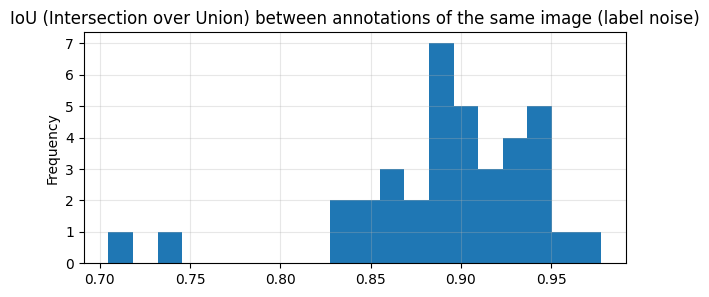

In [14]:
def dhash(p, size=8):
    g = Image.open(p).convert("L").resize((size + 1, size), Image.BILINEAR)
    a = np.asarray(g, dtype=np.int16)
    return np.packbits((a[:, 1:] > a[:, :-1]).ravel())

H  = np.stack([dhash(p) for p in meta.path])                                         # (N, 8) uint8
TH = np.stack([cv2.resize(cv2.imread(str(p), cv2.IMREAD_GRAYSCALE), (64, 64), interpolation=cv2.INTER_AREA)
               for p in meta.path]).astype(np.float32)                                # thumbnail

# Candidate pairs: same frame name or same dHash -> verified via pixel comparison; grouped using union-find.
parent = list(range(len(meta)))
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]; i = parent[i]
    return i
cands = set()
for key in [meta.frame, pd.Series([h.tobytes() for h in H])]:
    for idx in pd.Series(range(len(meta))).groupby(key.values).groups.values():
        idx = list(idx); cands |= {(a, b) for k, a in enumerate(idx) for b in idx[k + 1:]}
for a, b in cands:
    if np.abs(TH[a] - TH[b]).mean() < 3:
        parent[find(a)] = find(b)
meta["dup_group"] = [find(i) for i in range(len(meta))]

same_name = meta.groupby("frame").filter(lambda g: len(g) > 1)
print(f"Group with the same frame name: {same_name.frame.nunique()} | that actually overlap in pixels: "
      f"{same_name.groupby('frame').dup_group.nunique().eq(1).sum()}")
g = meta.groupby("dup_group").agg(n=("name", "size"), splits=("split", lambda s: ",".join(sorted(set(s)))))
g = g[g.n > 1]
print(f"Group of perfectly matching images: {len(g)} group, {g.n.sum()} image -> {g.n.sum() - len(g)} redundant images can be removed")
display(g.splits.value_counts().rename("number of groups").to_frame().rename_axis("split contains copies"))

# Do the labels match for the same image? (measuring labeling noise)
noise = []
for _, grp in meta[meta.dup_group.isin(g.index) & (meta.split != "test")].groupby("dup_group"):
    labs = [read_labels(p) for p in grp.path]
    for a in range(len(labs)):
        for b in range(a + 1, len(labs)):
            A, B = labs[a], labs[b]
            ious = [max((iou_xywh(x[1:], y[1:]) for y in B), default=0) for x in A]
            noise.append(dict(same_count=len(A) == len(B), mean_iou=np.mean(ious) if ious else np.nan))
noise = pd.DataFrame(noise)
if len(noise):
    print(f"A pair of duplicates with the same box number: {noise.same_count.mean():.1%} | Average IoU between two labeling instances: {noise.mean_iou.mean():.3f}")
    noise.mean_iou.plot.hist(bins=20, figsize=(7, 3), title="IoU (Intersection over Union) between annotations of the same image (label noise)"); plt.show()

valid: 24.3% Images with near-duplicates (Hamming distance ≤ 5) in the training set
test: 40.3% Images with near-duplicates (Hamming distance ≤ 5) in the training set


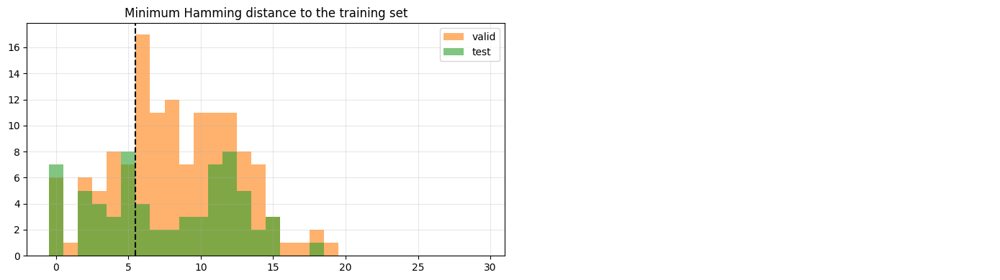

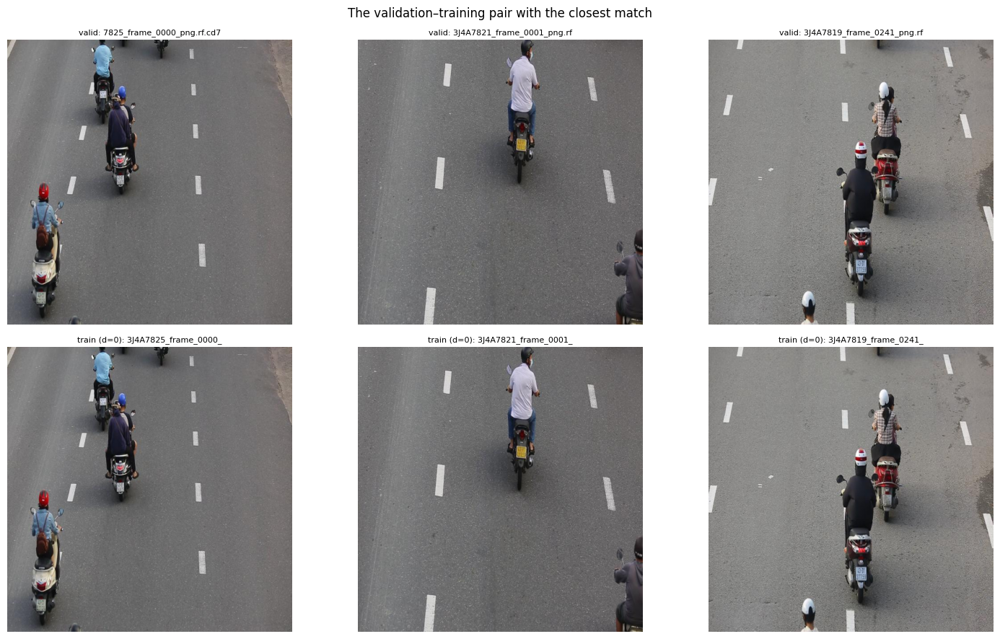

In [16]:
# --- Near overlap (leakage due to adjacent frames) ---
def hamming(A, B):
    return np.unpackbits(A[:, None, :] ^ B[None, :, :], axis=-1).sum(-1)

tr = (meta.split == "train").values
D = {s: hamming(H[(meta.split == s).values], H[tr]) for s in ["valid", "test"]}
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for s, c in [("valid", "C1"), ("test", "C2")]:
    m = D[s].min(1)
    ax[0].hist(m, bins=np.arange(-.5, 30.5), alpha=.6, label=s, color=c)
    print(f"{s}: {np.mean(m <= 5) * 100:.1f}% Images with near-duplicates (Hamming distance ≤ 5) in the training set")
ax[0].axvline(5.5, ls="--", c="k"); ax[0].set_title("Minimum Hamming distance to the training set"); ax[0].legend()

# For example, the validation-training pair is nearly identical:
vi = np.where(meta.split == "valid")[0]; ti = np.where(tr)[0]
order = np.argsort(D["valid"].min(1))[:3]
ax[1].axis("off")
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for k, i in enumerate(order):
    j = D["valid"][i].argmin()
    axes[0, k].imshow(Image.open(meta.path.iloc[vi[i]])); axes[0, k].set_title("valid: " + meta.name.iloc[vi[i]][:26], fontsize=8)
    axes[1, k].imshow(Image.open(meta.path.iloc[ti[j]])); axes[1, k].set_title(f"train (d={D['valid'][i, j]}): " + meta.name.iloc[ti[j]][:20], fontsize=8)
for a in axes.ravel(): a.axis("off")
plt.suptitle("The validation–training pair with the closest match"); plt.tight_layout(); plt.show()

**Conclusion of Section 4** (Kaggle run of v1, 2026-10-08)

| Finding | Numbers | Meaning |
|---|---|---|
| Same frame name | 182 groups, only 43 are pixel-identical | File names cannot be trusted; pixels must be compared |
| Exact duplicates | 45 groups / 90 images (45 redundant) | The same image uploaded twice |
| …spanning splits | 7 test–train, 4 train–valid, 1 test–valid | Direct leakage |
| Label noise | 100% same box count, mean IoU 0.892 | Two annotations of the same image differ by ~11% |
| Near-duplicates of train (Hamming ≤ 5) | valid 24.3%, test 40.3% | Adjacent frames of the same video |

- Overall, image and label quality are acceptable, but the original split **suffers from leakage**: identical images and adjacent frames from the same video appear in both train and valid. Consequently, the mAP on the original validation set is **overly optimistic**. Section 5 addresses this issue.
- Two annotations of the same image only reach IoU ~0.89, so at IoU thresholds 0.9/0.95 even the annotator does not agree with themselves → **mAP@0.5:0.95 has a natural ceiling**; do not expect, or over-optimise, a high value for this metric.

## 5. Preprocessing

### 5.1 Data Cleaning & Creating Two Dataset Versions

| Step | A — Original Split | B — Cleaned + Video-based Split |
| --- | --- | --- |
| Clip boxes to $[0,1]$, remove degenerate/overlapping boxes, remove invalid classes | ✓ | ✓ |
| Remove duplicate image content (keep the version with the most boxes) | ✗ | ✓ |
| Train/val splitting | Keep Roboflow's original split | **GroupShuffleSplit by video**, ensuring no video appears in both sets |

Experiment A serves as the baseline, yielding an "optimistic" mAP inflated by data leakage. Experiment B provides a more honest and realistic evaluation of generalization performance on unseen videos.

In [17]:
def clean_labels(lab):
    # Clip boxes to image bounds, remove degenerate boxes, invalid classes, and overlapping boxes
    if lab is None or len(lab) == 0:
        return np.zeros((0, 5))
    out = []
    for c, cx, cy, w, h in lab:
        if int(c) not in range(len(CLASS_NAMES)):
            continue
        x1, y1 = np.clip(cx - w / 2, 0, 1), np.clip(cy - h / 2, 0, 1)
        x2, y2 = np.clip(cx + w / 2, 0, 1), np.clip(cy + h / 2, 0, 1)
        w, h = x2 - x1, y2 - y1
        if w < MIN_WH or h < MIN_WH:
            continue
        b = np.array([c, (x1 + x2) / 2, (y1 + y2) / 2, w, h])
        if any(iou_xywh(b[1:], o[1:]) > 0.9 for o in out):
            continue
        out.append(b)
    return np.array(out).reshape(-1, 5)

def build_dataset(name, assignment):
    # assignment: list of (img_path, subset) with subset in {'train','val'}
    root = DS_ROOT / name
    if root.exists(): shutil.rmtree(root)
    n_box = 0
    for p, sub in assignment:
        (root / sub / "images").mkdir(parents=True, exist_ok=True)
        (root / sub / "labels").mkdir(parents=True, exist_ok=True)
        shutil.copy(p, root / sub / "images" / p.name)
        lab = clean_labels(read_labels(p))
        n_box += len(lab)
        (root / sub / "labels" / (p.stem + ".txt")).write_text(
            "\n".join(f"{int(c)} {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}" for c, cx, cy, w, h in lab))
    cfg = dict(path=str(root), train="train/images", val="val/images", nc=len(CLASS_NAMES), names=CLASS_NAMES)
    yaml.safe_dump(cfg, open(root / "data.yaml", "w"), sort_keys=False)
    print(f"[{name}] train={sum(s == 'train' for _, s in assignment)} val={sum(s == 'val' for _, s in assignment)} boxes={n_box}")
    return root / "data.yaml"

labelled = meta[meta.split != "test"].copy()

# ---- A: Original split ----
YAML_A = build_dataset("A_original", [(r.path, "train" if r.split == "train" else "val") for _, r in labelled.iterrows()])

# ---- B: Remove duplicates + video-based split ----
from sklearn.model_selection import GroupShuffleSplit
labelled["n_box"] = [0 if (l := read_labels(p)) is None else len(l) for p in labelled.path]
dedup = (labelled.sort_values(["n_box", "split", "name"], ascending=[False, True, True])
         .drop_duplicates("dup_group", keep="first").reset_index(drop=True))
print(f"Removed duplicates: {len(labelled)} -> {len(dedup)} images")

# Try multiple seeds, select the split with validation ratio closest to VAL_FRAC and having >= 2 validation videos
best = None
for seed in range(500):
    gss = GroupShuffleSplit(n_splits=1, test_size=VAL_FRAC, random_state=seed)
    tr_idx, va_idx = next(gss.split(dedup, groups=dedup.video))
    frac = len(va_idx) / len(dedup)
    if dedup.video.iloc[va_idx].nunique() >= 2 and (best is None or abs(frac - VAL_FRAC) < best[0]):
        best = (abs(frac - VAL_FRAC), tr_idx, va_idx)
_, tr_idx, va_idx = best
dedup["subset"] = "train"; dedup.loc[va_idx, "subset"] = "val"
VAL_VIDEOS = sorted(dedup.loc[va_idx, "video"].unique())
print("Validation videos:", VAL_VIDEOS, f"| validation ratio = {len(va_idx) / len(dedup):.1%}")
YAML_B = build_dataset("B_video_split", list(zip(dedup.path, dedup.subset)))

[A_original] train=1152 val=136 boxes=1924
Removed duplicates: 1288 -> 1251 images
Validation videos: ['7817', '7825'] | validation ratio = 15.1%
[B_video_split] train=1062 val=189 boxes=1870


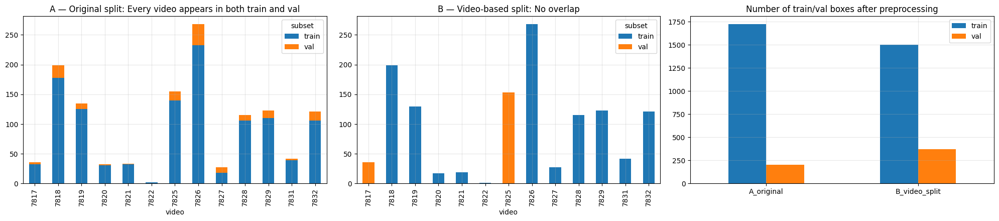

,train,val
A_original,1723,201
B_video_split,1501,369


In [18]:
fig, ax = plt.subplots(1, 3, figsize=(20, 4.5))
A_sub = labelled.assign(subset=np.where(labelled.split == "train", "train", "val"))
pd.crosstab(A_sub.video, A_sub.subset).plot.bar(stacked=True, ax=ax[0], color=["C0", "C1"])
ax[0].set_title("A — Original split: Every video appears in both train and val")
pd.crosstab(dedup.video, dedup.subset).reindex(columns=["train", "val"], fill_value=0).plot.bar(stacked=True, ax=ax[1], color=["C0", "C1"])
ax[1].set_title("B — Video-based split: No overlap")

def box_counts(yaml_path):
    root = Path(yaml_path).parent
    return {s: sum(len(open(f).read().split("\n")) if open(f).read().strip() else 0 for f in (root / s / "labels").glob("*.txt")) for s in ["train", "val"]}
cmp = pd.DataFrame({"A_original": box_counts(YAML_A), "B_video_split": box_counts(YAML_B)}).T
cmp.plot.bar(ax=ax[2], rot=0); ax[2].set_title("Number of train/val boxes after preprocessing")
plt.tight_layout(); plt.show()
display(cmp)

**Conclusion of Section 5** (Kaggle run of v1, 2026-10-08)

| | A — original split | B — cleaned + video-based split |
|---|---|---|
| Train / val images | 1152 / 136 | 1062 / 189 |
| Train / val boxes | 1723 / 201 | 1501 / 369 |
| Boxes/image train / val | 1.50 / 1.48 | 1.41 / **1.95** |
| Validation videos | every video | `7817`, `7825` (15.1% of images) |

- Deduplication: 1288 → 1251 images (37 removed, not 45, because some copies sit in the unlabeled test set).
- ⚠️ **B's validation set is more crowded than its train set** (1.95 vs 1.41 boxes/image) → B's val may simply be harder, not just leakage-free. The A − B gap in Section 7.2 = leakage **+** difficulty difference, not leakage alone.
- ⚠️ **B's validation set contains only 2 videos** → high-variance estimate; picking 2 other videos could give a very different mAP. For a more reliable estimate: cross-validation by video (GroupKFold).
- ⚠️ Images were **stretched** (see the Section 3 observations): when deploying on raw video, preprocessing must match training.

### 5.2 Augmentation (Online, Handled by Ultralytics During Training)

Choices based on EDA findings:

* The dataset is small (~1k images) with limited contexts (a few fixed cameras), so strong **mosaic + scale + translate** are used to increase scene and size diversity.
* Tall and narrow bounding boxes (motorcycles viewed frontally/sideways): use **horizontal flipping**, **no vertical flipping**, and mild rotation ($\pm 5^\circ$).
* Brightness is similar across splits (Section 4.1) but widely spread within each split (≈ 57–149), and new videos/cameras may differ: use **HSV** augmentation (especially `hsv_v`) to make the model robust to lighting changes.
* Light `mixup` to reduce overfitting; `close_mosaic` disables mosaic for the final 10 epochs to help the model fine-tune on real, uncropped images.

Pixel normalization to $[0,1]$ and letterboxing to `imgsz` are handled automatically by Ultralytics.

train: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1604.6±567.4 MB/s, size: 66.4 KB)
train: Scanning /kaggle/working/datasets/B_video_split/train/labels... 1062 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1062/1062 1.1Kit/s 1.0s1ss
train: New cache created: /kaggle/working/datasets/B_video_split/train/labels.cache
albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, method='weighted_average', num_output_channels=3), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))


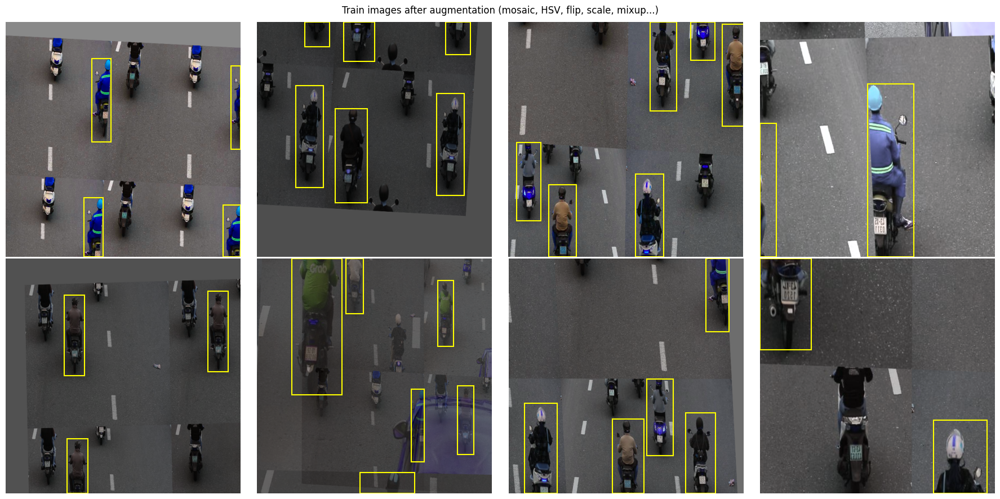

In [19]:
AUG = dict(
    hsv_h=0.015, hsv_s=0.6, hsv_v=0.45,
    degrees=5.0, translate=0.1, scale=0.5, shear=2.0, perspective=0.0,
    flipud=0.0, fliplr=0.5,
    mosaic=1.0, mixup=0.1, close_mosaic=10,
)

def preview_augmentation(data_yaml, n=8, cols=4):
    from ultralytics.cfg import get_cfg
    from ultralytics.data import build_yolo_dataset
    from ultralytics.data.utils import check_det_dataset
    data = check_det_dataset(str(data_yaml))
    cfg = get_cfg(overrides={**AUG, "imgsz": IMGSZ, "data": str(data_yaml)})
    ds = build_yolo_dataset(cfg, data["train"], batch=BATCH, data=data, mode="train")
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4.5 * cols, 4.5 * rows))
    for ax, i in zip(np.ravel(axes), random.sample(range(len(ds)), n)):
        s = ds[i]
        img = s["img"].permute(1, 2, 0).numpy()[..., ::-1]     # CHW BGR -> HWC RGB
        Hh, Ww = img.shape[:2]
        ax.imshow(img); ax.axis("off")
        for cx, cy, w, h in s["bboxes"].numpy():
            ax.add_patch(patches.Rectangle(((cx - w / 2) * Ww, (cy - h / 2) * Hh), w * Ww, h * Hh, fill=False, ec="yellow", lw=1.5))
    plt.suptitle("Train images after augmentation (mosaic, HSV, flip, scale, mixup...)"); plt.tight_layout(); plt.show()

try:
    preview_augmentation(YAML_B)
except Exception as e:
    print("Could not preview augmentation:", repr(e), "— check train_batch*.jpg after training.")

## 6. Training
Both experiments use the same model, the same hyperparameters and the same augmentation; **only the data differs**:
- **A**: original split (baseline, leaky)
- **B**: cleaned data, split by video

In [20]:
from ultralytics import YOLO

def train_run(name, data_yaml):
    model = YOLO(MODEL)
    model.train(
        data=str(data_yaml), epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, patience=PATIENCE,
        optimizer="auto", cos_lr=True, seed=SEED, deterministic=True,
        project=str(RUNS), name=name, exist_ok=True, plots=True,
        workers=WORKERS, fraction=FRACTION, **AUG,
    )
    return Path(model.trainer.save_dir)
print("Successfully installation def train_run!")

Successfully installation def train_run!


In [21]:
RUN_DIRS = {}
RUN_DIRS["A_original"] = train_run("A_original", YAML_A)

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/datasets/A_original/data.yaml, degrees=5.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.6, hsv_v=0.45, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=A_original, nbs=64, nms=None, opset=None, op

In [23]:
RUN_DIRS["B_video_split"] = train_run("B_video_split", YAML_B)
RUN_DIRS

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/datasets/B_video_split/data.yaml, degrees=5.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.6, hsv_v=0.45, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=B_video_split, nbs=64, nms=None, opset=No

{'A_original': PosixPath('/kaggle/working/runs/A_original'),
 'B_video_split': PosixPath('/kaggle/working/runs/B_video_split')}

## 7. Evaluation
### 7.1 Training curves: comparing A and B, checking for overfitting

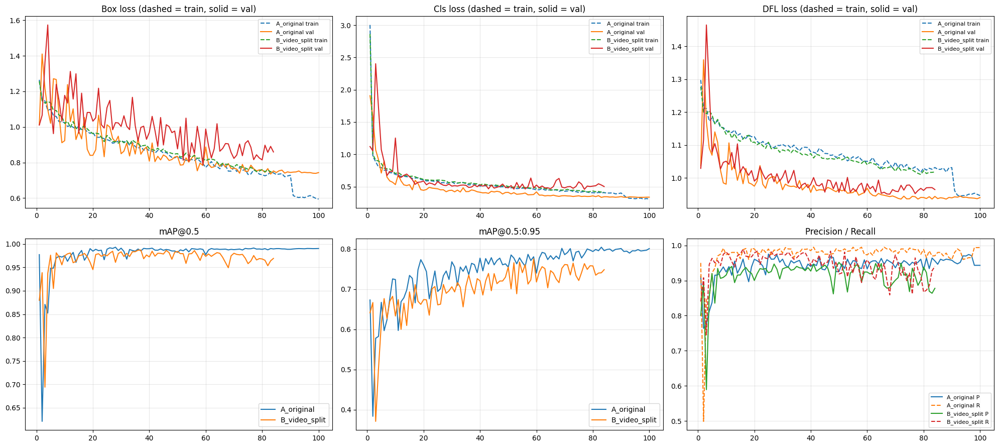

,best_epoch,epochs_run,val/box_loss − train/box_loss (last)
A_original,83.0,100.0,0.1490
B_video_split,59.0,84.0,0.1145


In [24]:
hist = {}
for k, d in RUN_DIRS.items():
    r = pd.read_csv(d / "results.csv"); r.columns = r.columns.str.strip(); hist[k] = r

fig, ax = plt.subplots(2, 3, figsize=(20, 9))
plots = [("train/box_loss", "val/box_loss", "Box loss"), ("train/cls_loss", "val/cls_loss", "Cls loss"),
         ("train/dfl_loss", "val/dfl_loss", "DFL loss")]
for i, (tr_k, va_k, t) in enumerate(plots):
    for k, r in hist.items():
        ax[0, i].plot(r.epoch, r[tr_k], "--", label=f"{k} train")
        ax[0, i].plot(r.epoch, r[va_k], "-", label=f"{k} val")
    ax[0, i].set_title(t + " (dashed = train, solid = val)"); ax[0, i].legend(fontsize=8)
for i, (m, t) in enumerate([("metrics/mAP50(B)", "mAP@0.5"), ("metrics/mAP50-95(B)", "mAP@0.5:0.95")]):
    for k, r in hist.items():
        ax[1, i].plot(r.epoch, r[m], label=k)
    ax[1, i].set_title(t); ax[1, i].legend()
for k, r in hist.items():
    ax[1, 2].plot(r.epoch, r["metrics/precision(B)"], label=f"{k} P")
    ax[1, 2].plot(r.epoch, r["metrics/recall(B)"], "--", label=f"{k} R")
ax[1, 2].set_title("Precision / Recall"); ax[1, 2].legend(fontsize=8)
plt.tight_layout(); plt.show()

gap = pd.DataFrame({k: {"best_epoch": int(r.loc[r["metrics/mAP50-95(B)"].idxmax(), "epoch"]),
                        "epochs_run": len(r),
                        "val/box_loss − train/box_loss (last)": round(r["val/box_loss"].iloc[-1] - r["train/box_loss"].iloc[-1], 4)}
                    for k, r in hist.items()}).T
display(gap)

### 7.2 Validation metrics with `best.pt`

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 11,125,971 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1719.4±423.0 MB/s, size: 65.8 KB)
val: Scanning /kaggle/working/datasets/A_original/val/labels.cache... 136 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 136/136 40.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 2.8it/s 3.2s0.3ss
                   all        136        201      0.964       0.97       0.99      0.806
Speed: 3.0ms preprocess, 10.0ms inference, 0.0ms loss, 3.7ms postprocess per image
Results saved to /kaggle/working/runs/val_A_original
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 11,125,971 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1408.0±330.9 MB/s, size: 46.2 

,precision,recall,mAP@0.5,mAP@0.75,mAP@0.5:0.95
A_original,0.9640,0.9701,0.9902,0.9676,0.8059
B_video_split,0.9244,0.9458,0.9803,0.9504,0.7752


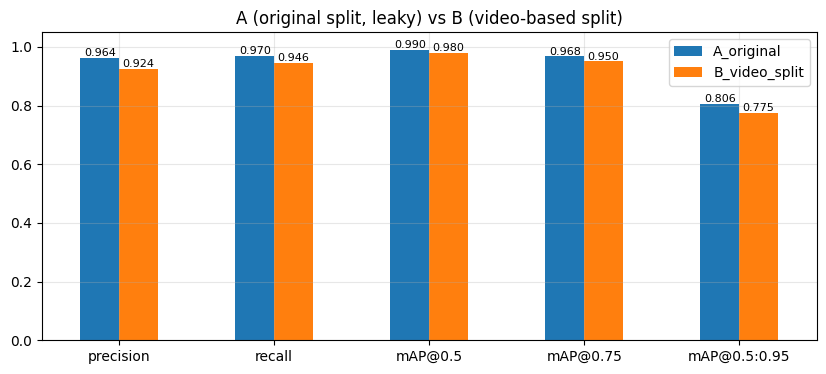

mAP@0.5:0.95 gap (A − B) = leakage + difficulty difference of B's val (see the Section 5 conclusion): 0.0307


In [25]:
YAMLS = {"A_original": YAML_A, "B_video_split": YAML_B}
METRICS, MODELS = {}, {}
for k, d in RUN_DIRS.items():
    MODELS[k] = YOLO(str(d / "weights" / "best.pt"))
    METRICS[k] = MODELS[k].val(data=str(YAMLS[k]), imgsz=IMGSZ, batch=BATCH, project=str(RUNS),
                               name=f"val_{k}", exist_ok=True, plots=True, verbose=False)

score = pd.DataFrame({k: {"precision": m.box.mp, "recall": m.box.mr, "mAP@0.5": m.box.map50,
                          "mAP@0.75": m.box.map75, "mAP@0.5:0.95": m.box.map}
                      for k, m in METRICS.items()}).T.round(4)
display(score)
ax = score.T.plot.bar(rot=0, figsize=(10, 4), title="A (original split, leaky) vs B (video-based split)")
for c in ax.containers: ax.bar_label(c, fmt="%.3f", fontsize=8)
plt.ylim(0, 1.05); plt.show()
print("mAP@0.5:0.95 gap (A − B) = leakage + difficulty difference of B's val (see the Section 5 conclusion):", round(score.loc["A_original", "mAP@0.5:0.95"] - score.loc["B_video_split", "mAP@0.5:0.95"], 4))

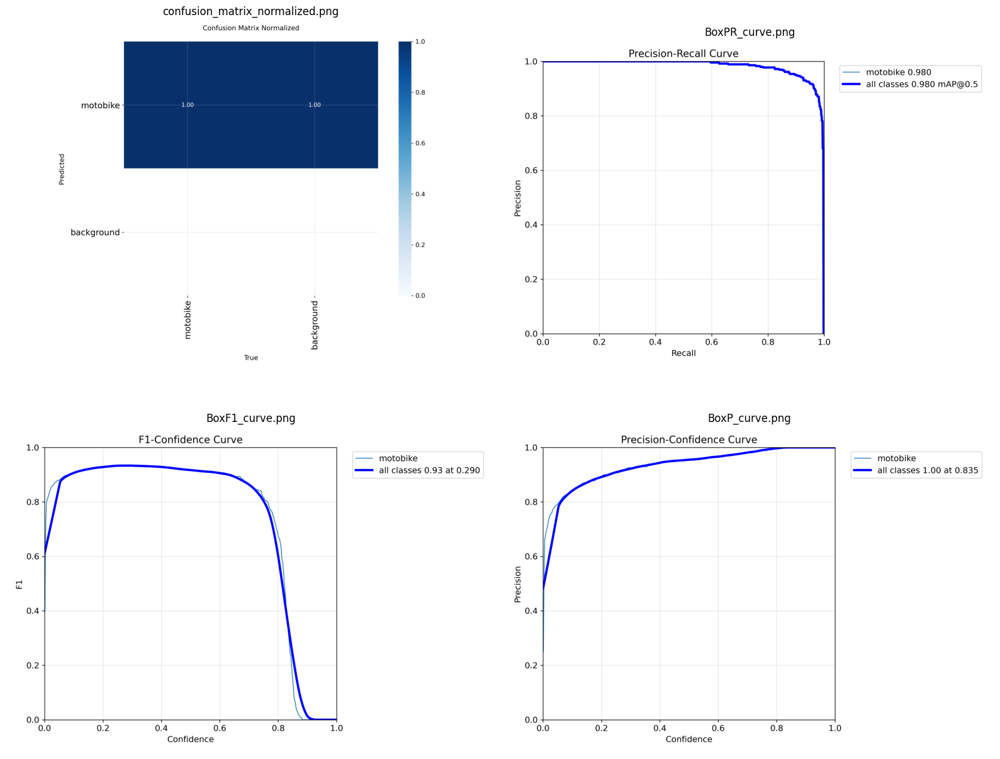

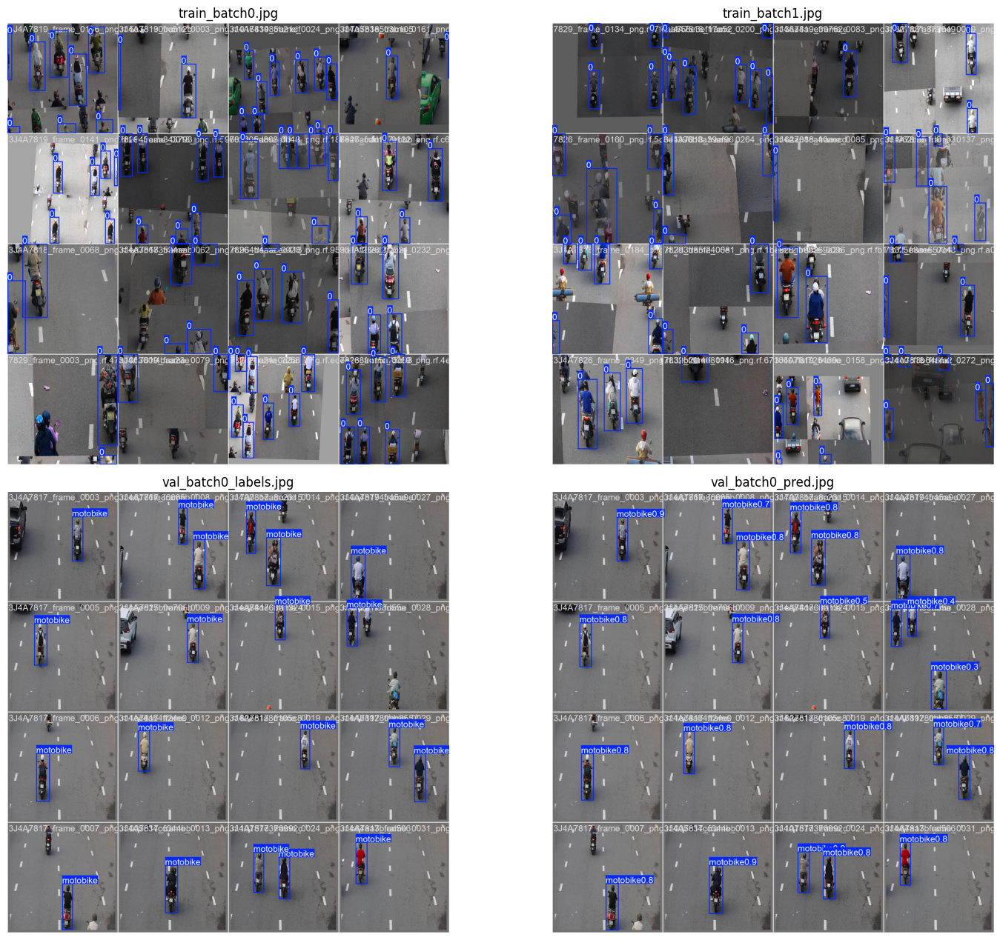

In [27]:
FINAL = "B_video_split"          # model used for the rest of the notebook
FINAL_MODEL, FINAL_DIR = MODELS[FINAL], RUN_DIRS[FINAL]

def show_imgs(paths, cols=2, size=8):
    paths = [p for p in paths if Path(p).exists()]
    if not paths: return
    rows = int(np.ceil(len(paths) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * .8 * rows))
    for ax, p in zip(np.ravel(axes), paths):
        ax.imshow(Image.open(p)); ax.set_title(Path(p).name); ax.axis("off")
    for ax in np.ravel(axes)[len(paths):]: ax.axis("off")
    plt.tight_layout(); plt.show()

def first_existing(d, names):
    return next((d / n for n in names if (d / n).exists()), d / names[0])

show_imgs([first_existing(FINAL_DIR, ["confusion_matrix_normalized.png", "confusion_matrix.png"]),
           first_existing(FINAL_DIR, ["BoxPR_curve.png", "PR_curve.png"]),
           first_existing(FINAL_DIR, ["BoxF1_curve.png", "F1_curve.png"]),
           first_existing(FINAL_DIR, ["BoxP_curve.png", "P_curve.png"])])
show_imgs(sorted(FINAL_DIR.glob("train_batch*.jpg"))[:2] + [FINAL_DIR / "val_batch0_labels.jpg", FINAL_DIR / "val_batch0_pred.jpg"])

### 7.3 Choosing the optimal confidence threshold (by F1)

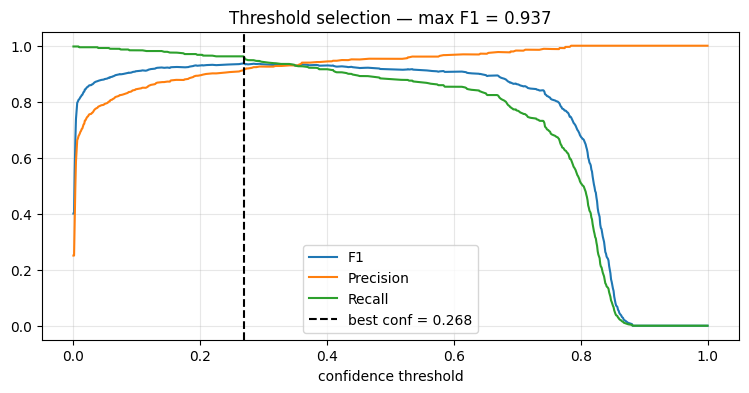

BEST_CONF = 0.268


In [28]:
m = METRICS[FINAL]
try:
    px, f1 = np.asarray(m.box.px), np.asarray(m.box.f1_curve).mean(0)
    p_c, r_c = np.asarray(m.box.p_curve).mean(0), np.asarray(m.box.r_curve).mean(0)
    BEST_CONF = float(px[f1.argmax()])
    plt.figure(figsize=(9, 4))
    plt.plot(px, f1, label="F1"); plt.plot(px, p_c, label="Precision"); plt.plot(px, r_c, label="Recall")
    plt.axvline(BEST_CONF, ls="--", c="k", label=f"best conf = {BEST_CONF:.3f}")
    plt.xlabel("confidence threshold"); plt.legend(); plt.title(f"Threshold selection — max F1 = {f1.max():.3f}"); plt.show()
except Exception as e:
    BEST_CONF = 0.25
    print("Could not read the F1 curve:", e)
BEST_CONF = float(np.clip(BEST_CONF, 0.05, 0.9))
print("BEST_CONF =", round(BEST_CONF, 3))

### 7.4 Error analysis on validation (B)
Match predictions with ground truth (IoU ≥ 0.5) to count **TP / FP / FN**, compute recall by box size, and show the images with the most errors.
Colours: <span style="color:green">missed GT (FN)</span>, <span style="color:blue">correct prediction (TP)</span>, <span style="color:red">wrong prediction (FP)</span>.

conf=0.268 | TP=355 FP=85 FN=14 | P=0.807 R=0.962


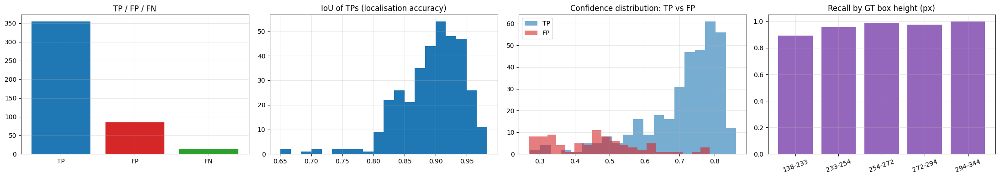

In [29]:
def xywhn_to_xyxy(lab, W, H):
    cx, cy, w, h = lab[:, 1] * W, lab[:, 2] * H, lab[:, 3] * W, lab[:, 4] * H
    return np.stack([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], 1)

def iou_matrix(a, b):
    if len(a) == 0 or len(b) == 0: return np.zeros((len(a), len(b)))
    x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area = lambda z: (z[:, 2] - z[:, 0]) * (z[:, 3] - z[:, 1])
    return inter / (area(a)[:, None] + area(b)[None, :] - inter + 1e-9)

val_root = Path(YAML_B).parent / "val"
val_imgs = sorted((val_root / "images").glob("*"))
err_rows, gt_rows, per_image = [], [], []
for r in FINAL_MODEL.predict([str(p) for p in val_imgs], imgsz=IMGSZ, conf=BEST_CONF, verbose=False, stream=True):
    p = Path(r.path); H_, W_ = r.orig_shape
    gl = np.loadtxt(val_root / "labels" / (p.stem + ".txt"), ndmin=2).reshape(-1, 5)
    gt = xywhn_to_xyxy(gl, W_, H_)
    pb, pc = r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy()
    iou = iou_matrix(pb, gt); matched_gt, tp = set(), np.zeros(len(pb), bool)
    for i in np.argsort(-pc):
        if iou.shape[1] == 0: break
        j = int(np.argmax(np.where([k in matched_gt for k in range(len(gt))], -1, iou[i])))
        if iou[i, j] >= 0.5 and j not in matched_gt:
            tp[i] = True; matched_gt.add(j); err_rows.append(dict(type="TP", conf=pc[i], iou=iou[i, j]))
    for i in np.where(~tp)[0]: err_rows.append(dict(type="FP", conf=pc[i], iou=iou[i].max() if iou.shape[1] else 0))
    for j in range(len(gt)):
        gt_rows.append(dict(h_px=gt[j, 3] - gt[j, 1], w_px=gt[j, 2] - gt[j, 0], detected=j in matched_gt))
    per_image.append(dict(path=p, gt=gt, pb=pb, tp=tp, matched=matched_gt, fp=int((~tp).sum()), fn=len(gt) - len(matched_gt)))

err = pd.DataFrame(err_rows, columns=["type", "conf", "iou"])
gtdf, pim = pd.DataFrame(gt_rows), pd.DataFrame(per_image)
n_tp, n_fp, n_fn = (err.type == "TP").sum(), (err.type == "FP").sum(), (~gtdf.detected).sum()
print(f"conf={BEST_CONF:.3f} | TP={n_tp} FP={n_fp} FN={n_fn} | P={n_tp / max(n_tp + n_fp, 1):.3f} R={n_tp / max(n_tp + n_fn, 1):.3f}")

fig, ax = plt.subplots(1, 4, figsize=(22, 4))
ax[0].bar(["TP", "FP", "FN"], [n_tp, n_fp, n_fn], color=["C0", "C3", "C2"]); ax[0].set_title("TP / FP / FN")
if n_tp: ax[1].hist(err[err.type == "TP"].iou, bins=20, color="C0"); ax[1].set_title("IoU of TPs (localisation accuracy)")
for t, c in [("TP", "C0"), ("FP", "C3")]:
    if (err.type == t).any(): ax[2].hist(err[err.type == t].conf, bins=20, alpha=.6, label=t, color=c)
ax[2].set_title("Confidence distribution: TP vs FP"); ax[2].legend()
gtdf["h_bin"] = pd.cut(gtdf.h_px, bins=np.quantile(gtdf.h_px, [0, .2, .4, .6, .8, 1]), include_lowest=True)
rec = gtdf.groupby("h_bin").detected.mean()
ax[3].bar(range(len(rec)), rec.values, color="C4"); ax[3].set_xticks(range(len(rec)))
ax[3].set_xticklabels([f"{i.left:.0f}-{i.right:.0f}" for i in rec.index], rotation=20)
ax[3].set_ylim(0, 1.05); ax[3].set_title("Recall by GT box height (px)")
plt.tight_layout(); plt.show()

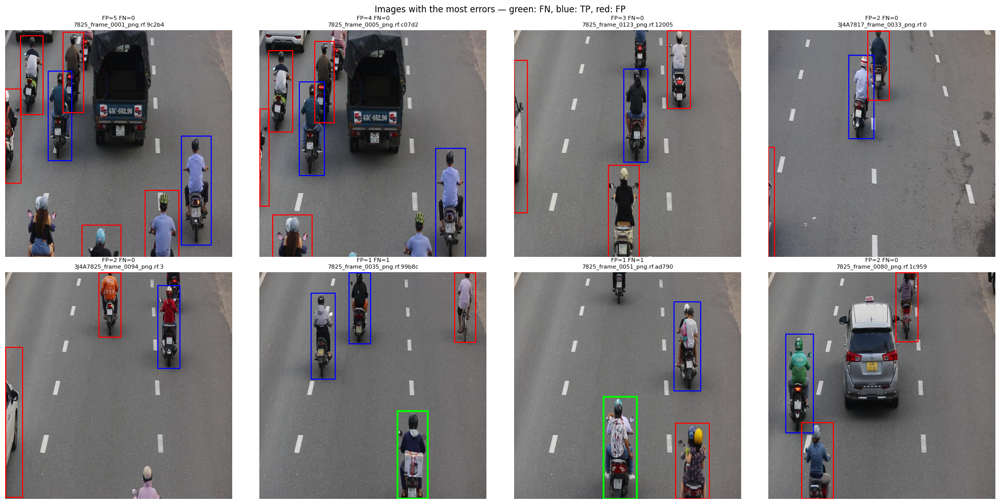

In [30]:
worst = pim.assign(err=pim.fp + pim.fn).sort_values("err", ascending=False)
worst = worst[worst.err > 0].head(8)
if len(worst) == 0:
    print("No image has errors at this threshold 🎉")
else:
    cols = 4; rows = int(np.ceil(len(worst) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 5 * rows))
    for ax, r in zip(np.ravel(axes), worst.to_dict("records")):
        ax.imshow(Image.open(r["path"])); ax.axis("off"); ax.set_title(f"FP={r['fp']} FN={r['fn']}\n{r['path'].name[:28]}", fontsize=8)
        for j, b in enumerate(r["gt"]):
            if j not in r["matched"]: ax.add_patch(patches.Rectangle(b[:2], b[2] - b[0], b[3] - b[1], fill=False, ec="lime", lw=2.5))
        for b, t in zip(r["pb"], r["tp"]):
            ax.add_patch(patches.Rectangle(b[:2], b[2] - b[0], b[3] - b[1], fill=False, ec="blue" if t else "red", lw=1.5))
    for ax in np.ravel(axes)[len(worst):]: ax.axis("off")
    plt.suptitle("Images with the most errors — green: FN, blue: TP, red: FP"); plt.tight_layout(); plt.show()

## 8. Inference on the test set (no labels)
Note: some test images are identical or near-identical to train images (see Section 4.3), so results on those images will look better than reality.

Results saved to /kaggle/working/runs/test_pred
67 labels saved to /kaggle/working/runs/test_pred/labels
67 test images | 119 boxes | images without boxes: 0 | test images identical to a train image: 8


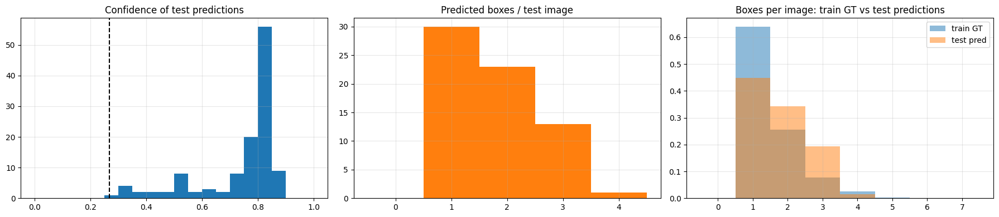

In [ ]:
test_meta = meta[meta.split == "test"].reset_index(drop=True)
test_meta["dup_in_train"] = test_meta.dup_group.isin(dedup.loc[dedup.subset == "train", "dup_group"])
preds = list(FINAL_MODEL.predict([str(p) for p in test_meta.path], imgsz=IMGSZ, conf=BEST_CONF,
                                 save=True, save_txt=True, save_conf=True, project=str(RUNS),
                                 name="test_pred", exist_ok=True, verbose=False, stream=True))
rows = []
for p, r in zip(test_meta.path, preds):
    for b, c, cf in zip(r.boxes.xyxy.cpu().numpy(), r.boxes.cls.cpu().numpy(), r.boxes.conf.cpu().numpy()):
        rows.append(dict(image=p.name, cls=CLASS_NAMES[int(c)], conf=float(cf), x1=b[0], y1=b[1], x2=b[2], y2=b[3]))
pred_df = pd.DataFrame(rows, columns=["image", "cls", "conf", "x1", "y1", "x2", "y2"])
pred_df.to_csv(WORK / "test_predictions.csv", index=False)
test_meta["n_pred"] = test_meta.name.map(pred_df.image.value_counts()).fillna(0).astype(int)
print(f"{len(test_meta)} test images | {len(pred_df)} boxes | images without boxes: {(test_meta.n_pred == 0).sum()} | "
      f"test images identical to a train image: {test_meta.dup_in_train.sum()}")

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
ax[0].hist(pred_df.conf, bins=20, range=(0, 1), color="C0"); ax[0].axvline(BEST_CONF, ls="--", c="k"); ax[0].set_title("Confidence of test predictions")
ax[1].hist(test_meta.n_pred, bins=np.arange(-.5, test_meta.n_pred.max() + 1.5), color="C1"); ax[1].set_title("Predicted boxes / test image")
ax[2].hist(boxes[boxes.split == "train"].groupby("img").size(), bins=np.arange(-.5, 8.5), alpha=.5, density=True, label="train GT")
ax[2].hist(test_meta.n_pred, bins=np.arange(-.5, 8.5), alpha=.5, density=True, label="test pred"); ax[2].legend()
ax[2].set_title("Boxes per image: train GT vs test predictions")
plt.tight_layout(); plt.show()

sample = random.sample(preds, min(8, len(preds)))
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
for ax, r in zip(np.ravel(axes), sample):
    ax.imshow(r.plot()[..., ::-1]); ax.axis("off"); ax.set_title(Path(r.path).name[:28], fontsize=8)
for ax in np.ravel(axes)[len(sample):]: ax.axis("off")
plt.suptitle(f"Test predictions (conf ≥ {BEST_CONF:.2f})"); plt.tight_layout(); plt.show()

## 9. Saving results

In [35]:
best_pt = FINAL_DIR / "weights" / "best.pt"
shutil.copy(best_pt, WORK / "motorbike_yolov8_best.pt")
try:
    onnx_path = YOLO(str(best_pt)).export(format="onnx", imgsz=IMGSZ, simplify=True)
    shutil.copy(onnx_path, WORK / "motorbike_yolov8_best.onnx")
except Exception as e:
    print("ONNX export failed:", e)
score.assign(best_conf=BEST_CONF).to_csv(WORK / "val_metrics.csv")
for k, d in RUN_DIRS.items():
    shutil.copy(d / "results.csv", WORK / f"results_{k}.csv")
shutil.rmtree(DS_ROOT, ignore_errors=True)    # delete the dataset copies to keep the output small
for f in sorted(WORK.glob("*")):
    print(f.name)

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
Model summary (fused): 72 layers, 11,125,971 parameters, 0 gradients, 28.4 GFLOPs

PyTorch: starting from '/kaggle/working/runs/B_video_split/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 5, 8400) (21.5 MB)

ONNX: starting export with onnx 1.22.0 opset 18...
ONNX: slimming with onnxslim 0.1.98...
ONNX: export success ✅ 1.7s, saved as '/kaggle/working/runs/B_video_split/weights/best.onnx' (42.7 MB)

Export complete (2.1s)
Results saved to /kaggle/working/runs/B_video_split/weights/best.onnx
Predict:         yolo predict task=detect model=/kaggle/working/runs/B_video_split/weights/best.onnx imgsz=640 
Validate:        yolo val task=detect model=/kaggle/working/runs/B_video_split/weights/best.onnx imgsz=640   
Visualize:       https://netron.app
.virtual_documents
motorbike_yolov8_best.onnx
motorbike_yolov8_best.pt
results_A_original.csv
results_B_video_split.csv
runs
t

## Summary
- **Preprocessing:** label cleaning, duplicate-frame removal, video-based train/val split to remove leakage; augmentation chosen from the data characteristics (tall narrow boxes, varying lighting, few scenes).
- **Evaluation:** **B**'s mAP is a more honest estimate for new videos. The A − B gap shows how optimistic the original split is, but discount it because B's val is more crowded and has only 2 videos. mAP@0.5:0.95 is capped by label noise (IoU between two annotations ≈ 0.89).
- **Outputs** (`/kaggle/working`): `motorbike_yolov8_best.pt`, `.onnx`, `val_metrics.csv`, `results_*.csv`, `test_predictions.csv`, `runs/`.